# Problem 1: Urgent care center

We assume the arrival of patients to a UCC follows a Poisson process with rate $\lambda > 0$, and that the treatment times are exponantially distributed with expectation $1/ \mu > 0$. One patient can be treated at a time. We assume the treatment times are independent of the arrival process. We assume no upper limit of the queue of patients.

We assume $\lambda < \mu$ and we let $X(t)$ denote the number of patients in the UCC at time t. We know that $X(0) = 0$.

In [23]:
# Required libraries

import numpy as np
from matplotlib import pyplot as plt
from scipy import stats

### Problem 1a)

We first state the conditions for the UCC to be an M/M/1 queue, and why theese conditions are satisfied.

An M/M/1 queue means the interarrival times are memoryless, the service times are memoryless and the number of servers is 1. As the interarrival times of a poisson process are exponentially distibuted (memoryless), the interarrival times of the UCC are memoryless. Further, the service times are exponentially distributed, i.e. memoryless as well. Finally, we know only one patient can be treated at a time, so the number of servers is 1. Thus, the UCC is an M/M/1 queue.

Further, we see that we can view the stochastic process $\{ X(t) : t \geq 0 \}$ as a birth-and-death process, meaning:


$
P_{ij}(t) = \operatorname{Pr}\{X(t+s) = j \mid X(s) = i\} \quad \text{for all} \quad s \ge 0.
$

In addition, we assume that the $P_{ij}(t)$ satisfy
1) $P_{i,i+1}(h) = \lambda_i h + o(h) \text{ as } h \downarrow 0, i \ge 0$;
2) $P_{i,i-1}(h) = \mu_i h + o(h) \text{ as } h \downarrow 0, i \ge 1$;
3) $P_{i,i}(h) = 1 - (\lambda_i + \mu_i)h + o(h) \text{ as } h \downarrow 0, i \ge 0$;
4) $P_{ij}(0) = \delta_{ij}$;
5) $\mu_0 = 0, \lambda_0 > 0, \mu_i, \lambda_i > 0, i = 1, 2, \dots$.



The first requirement is satisfied by the fact that the process is memoryless. Point 1 and 2 follow from the fact that the interarrival times and service times are exponentially distributed, and point 3 from the fact that we can only increase the queue by one or decrease it by one at a time. Point 4 follows from the fact that we assume $X(0) = 0$, and 5 follows form the parameters $\mu$ and $\lambda$ of our process.

We will now determine the average time a patient will spend in the UCC as a function of $\lambda$ and $\mu$. To do so, we use the queueing formula $L = \lambda W$. This means we will first have to calculate the expected queue length. As we have assumed $ \lambda < \mu$ we have an equilibrium distribution. We turn to the process of calculating the limiting distribution, and get:

$\theta_0 = 1$ and $\theta_j = \frac{\lambda_0 \lambda_1 ... \lambda_{j-1}}{\mu_1 \mu_2 ... \mu_{j}} = (\lambda / \mu)^j$ $\implies$ $\sum_{j=0}^{\infty} \theta_j = \frac{1}{1-\lambda / \mu}$ $\implies$ $\pi_0 = 1-\lambda / \mu$

$\pi_k = \pi_0 \theta_k = (1-\lambda / \mu) (\lambda / \mu)^k =(\lambda / \mu) (1-\lambda / \mu) (1 - (1 - \lambda / \mu))^{k-1}$ 

We regognize the geometric distribution with $p = 1 - \lambda / \mu$ (times a factor $\lambda / \mu$) meaning $L = \frac{\lambda}{\mu} \frac{1}{1-\lambda / \mu} = \frac{\lambda}{\mu-\lambda}$

This means $W = L/\lambda = \frac{1}{\mu - \lambda}$

### Problem 1b)

In [7]:
def simulate_birth_death_process(init_pop: int, end_time, lam_func, mu_func):
    times = [0.0]
    populations = [init_pop]

    t = 0
    pop = init_pop
    while t < end_time:
        lam = lam_func(pop)
        mu = mu_func(pop)

        if mu + lam == 0:
            times.append(end_time)
            populations.append(pop)
            break

        delta_time = np.random.exponential(1/(mu+lam))
        t += delta_time

        if t > end_time:
            break

        if np.random.rand() < lam/(mu+lam):
            pop += 1
        else: 
            pop -= 1

        populations.append(pop)
        times.append(t)

    return np.array(times), np.array(populations)

We assume $\lambda = 5$ patients per hour and $1/\mu = 10$ minutes, and run a simulation for 50 days. we use the second helf of the data to find an estimate for the expected time in the UCC by Little's law.

In [32]:
def lam_func(pop):
    return 5

def mu_func(pop):
    if pop > 0:
        return 6
    else:
        return 0

times, populations = simulate_birth_death_process(0, 50*24, lam_func, mu_func)

half_idx = len(populations) // 2
rest = len(populations) % 2
L_estimate = np.sum(populations[half_idx:]) / (half_idx + 1)
W_estimate = L_estimate/lam_func(0)

print(f"Estimated waiting time: {round(W_estimate, 2)} hours")

Estimated waiting time: 0.99 hours


We do the simulation 30 times and compute an approximate 95% confidence interval for the expected time a patient spends in the UCC.

In [50]:
def confidence_interval(values, confidence = 0.95):
    n_obs = len(values)
    mean = np.average(values)

    # ddof divides by n_obs-1
    std_error = stats.sem(values, ddof=1)

    #Critical value
    t_val = stats.t.ppf((1 + confidence) / 2.0, df=n_obs - 1)

    margin_of_error = t_val * std_error

    return mean, margin_of_error

In [52]:
n_sims = 30
W_estimates = np.zeros(n_sims)

for i in range(n_sims):
    times, populations = simulate_birth_death_process(0, 50*24, lam_func, mu_func)

    half_idx = len(populations) // 2
    rest = len(populations) % 2
    L_estimate = np.sum(populations[half_idx:]) / (half_idx + rest)
    W_estimate = L_estimate/lam_func(0)
    W_estimates[i] = W_estimate


mean, err = confidence_interval(W_estimates)


print(f"Mean: {mean:.4f}  (95% CI: [{(mean-err):.8f}, {(mean+err):.8f}])")

Mean: 1.0926  (95% CI: [1.01793425, 1.16730235])


We plot one realization of $\{ X(t) : t \geq 0 \}$ for 0-12 hours.

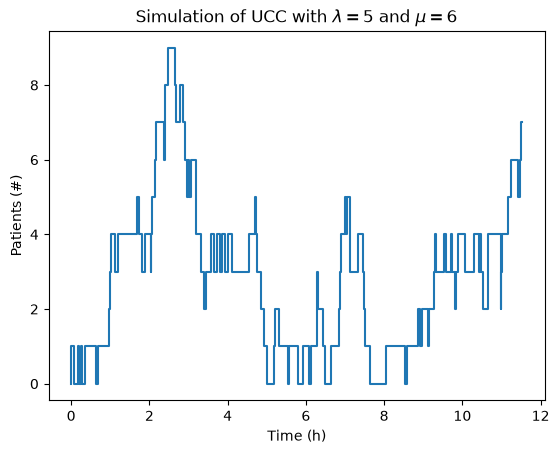

In [54]:
times, populations = simulate_birth_death_process(0, 12, lam_func, mu_func)

fig, ax = plt.subplots()
ax.step(times, populations)
ax.set(title = r"Simulation of UCC with $\lambda = 5$ and $\mu = 6$", xlabel = "Time (h)", ylabel = "Patients (#)")
plt.show()

TODO: Report) Briefly describe the steps you used to estimated the expected time, give the CI,
and compare the CI to the exact value computed using the expression from 1a).

### Problem 1c)

We now introduce a triage system to our UCC. Patients are assigned a priority urgent or normal upon arrival, and urgent patients are always treated before normal. If an urgent patient arrives while a normal patient is being treated, the normal patient will be moved back into the front of the queue. We let $U(t)$ and $N(t)$ denote the number of urgent and normal patients at time t. We have $X(t) = U(t) + N(t)$ and $U(0) = N(0) = 0$.

First, we would like to show that $\{ U(t) : t \geq 0 \}$ satisfies tha conditions of an M/M/1 queue. HOWWWWW???

The arrival rate of $\{ U(t) : t \geq 0 \}$ can be determined by simply seeing that it is $p\lambda$.

To determine the long run mean number of urgent patients in the UCC we observe that we can isolate the process $U(t)$. As the birth parameter is $p\lambda$ and death paramter is $\mu$ we have $L_U = \frac{p\lambda}{\mu-p\lambda}$

### Problem 1d)

To see why $\{ N(t) : t \geq 0 \}$ does not behave as an M/M/1 queue, we consider the cases where the number of normal patients is 1. When in state 1, we have to possible prior transitions: A transition from 2 to 1, and a transition from 0 to 1. A transition from 2 to 1 means there were only normal patients in the queue at the time of transition, so there is only one normal patient in the queue. A transition form 0 to 1 however, there is a nonzero probability that there are urgent patients already in the queue, which makes the probability of transition to state 2 next higher. The transition probabilities in state 1 is therefore clearly dependent on the previous state, and therefore not memoryless.

We would further like to determine the long-run mean number of normal patients in the UCC. We assume there exists a limiting distribution, and we denote it 

We have that $N(t) = X(t) - U(t)$, so:

$E[N(t)] = E[X(t) - U(t)] = E[X(t)] - E[U(t)]$

Taking the limit as $t \rightarrow \infty$ we get:

$L_N = E[N] = \frac{\lambda}{\mu-\lambda} - \frac{p\lambda}{\mu-p\lambda} = \frac{(1-p) \lambda \mu}{(\mu-\lambda)(\mu-p\lambda)}$

### Problem 1e)

We use littles law to find the expected time in the UCC for an urgent and normal patient. We use that the arrival rate of U is $p\lambda$ and the arrival rate of N is $(1-p) \lambda$ such that

$W_U = \frac{L_U}{p\lambda} = \frac{\frac{p\lambda}{\mu-p\lambda}}{p\lambda} = \frac{1}{\mu-p\lambda}$

$W_N = \frac{L_N}{(1-p)\lambda} = \frac{\frac{(1-p) \lambda \mu}{(\mu-\lambda)(\mu-p\lambda)}}{(1-p)\lambda} = \frac{\mu}{(\mu-\lambda)(\mu-p\lambda)}$

### Problem 1f)

We continue to assume $\lambda = 5$ patients per hour and $\mu = 6$ per hour. We will investigate how the expected time in the UCC varies as function of p. We start by plotting $W_U$ and $W_N$ as as a function of p.

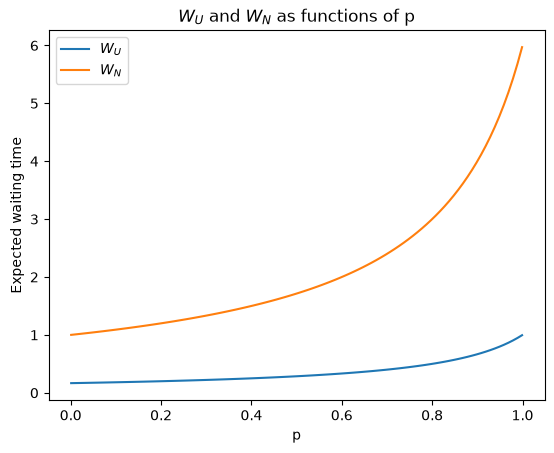

In [57]:
def W_U(lam, mu, p):
    return 1/(mu-p*lam)

def W_N(lam, mu, p):
    return mu/((mu-lam)*(mu-p*lam))

lam = 5
mu = 6

p_vals = np.linspace(0.001, 0.999, 100)

W_u = W_U(lam, mu, p_vals)
W_n = W_N(lam, mu, p_vals)

fig, ax = plt.subplots()
ax.plot(p_vals, W_u, label = r"$W_U$")
ax.plot(p_vals, W_n, label = r"$W_N$")
ax.set(title = "$W_U$ and $W_N$ as functions of p", xlabel = "p", ylabel = "Expected waiting time")
plt.legend()
plt.show()


We would also like to interpret the situations $p \approx 0$ and $p \approx 1$. In the first case, a patient arriving will almost certainly be a normal patient, and we expect $N(t)$ to behave like $X(t)$. We might also expect the average waiting time for urgent patients to we as if they always receive treatment immideatly. In the second case, a patient arriving will almost certainly be an urgent patient, and we expect $U(t)$ to behave like $X(t)$. We might also expect the average waiting time for a normal patient to become quite large.

We calculate the expected times in the extreme cases $p = 0$ and $p = 1$:

$\lim\limits_{p\to 0} W_U = \lim\limits_{p\to 0} \frac{1}{\mu-p\lambda} = \frac{1}{\mu}$

$\lim\limits_{p\to 0} W_N = \lim\limits_{p\to 0} \frac{\mu}{(\mu-\lambda)(\mu-p\lambda)} = \frac{1}{\mu-\lambda}$

$\lim\limits_{p\to 1} W_U = \lim\limits_{p\to 1} \frac{1}{\mu-p\lambda} = \frac{1}{\mu-\lambda}$

$\lim\limits_{p\to 1} W_N = \lim\limits_{p\to 1} \frac{\mu}{(\mu-\lambda)(\mu-p\lambda)} = \frac{\mu}{(\mu-\lambda)(\mu-\lambda)}$

We see that the values we get are coherent with our description of the process in the extreme cases.

### Problem 1g)

Assume that λ = 5 patients per hour, that 1/μ = 10 minutes, and that p = 0.80. Complete
the following tasks:
• (Computer code) Simulate {U (t) : t ≥ 0} and {N (t) : t ≥ 0} jointly for 50 days.
• (Computer code) Estimate the expected time in the UCC for an urgent patient, and esti-
mate the expected time in the UCC for a normal patient. Repeat 30 times to compute an
approximate 95% CI.
• (Report) Plot one joint realization of the total number of (normal and urgent) patients in
the UCC and the number of urgent patients in the UCC for time 0–12 hours in the same
figure. Colour them in different colours. The realizations must be displayed as series of
horizontal lines (and not continuous graphs).
• (Report) Briefly describe how you estimated the two quantities, give the two CIs, and
compare them to the exact numbers calculated using the expressions in 1e).